# 第 10 章 化腐朽为神奇：蒙特卡罗积分法 —— 代码实现

对应笔记 `docs/mc/ch10.md`。全章用同一目标 $I=\int_0^1\frac{4}{1+x^2}dx=\pi$（呼应第 1 章）。五个实验：方差账本（hit-or-miss vs 均值法）、重要性抽样、对偶/控制变量、分层/系统抽样、五法总决赛。

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch10")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

def g(x):
    return 4.0 / (1.0 + x*x)          # 目标函数，I = π

I = np.pi
rng = np.random.default_rng(2033)

## 10.1 方差账本：hit-or-miss vs 均值法

理论：均值法 $\mathrm{Var}=\frac{1}{N}\left(\int_0^1 g^2dx-I^2\right)=0.413/N$；hit-or-miss $=\frac{16(\pi/4)(1-\pi/4)}{N}=2.698/N$——差 6.5 倍。实测对撞。

In [20]:
N, reps = 100_000, 3000
g2_mean = 16 * (1/4 + np.pi/8)        # ∫ 16/(1+x²)² dx = 16(1/4 + π/8)
var_mean_t, var_hm_t = (g2_mean - I**2)/N, 16*(I/4)*(1 - I/4)/N

est_mean = np.array([g(rng.random(N)).mean() for _ in range(reps)])
est_hm = np.array([4*(rng.random(N) <= g(rng.random(N))/4).mean() for _ in range(reps)])
print(f"均值法:   实测 Var {est_mean.var():.3e} vs 理论 {var_mean_t:.3e}")
print(f"hit-or-miss: 实测 Var {est_hm.var():.3e} vs 理论 {var_hm_t:.3e}")
print(f"方差比 {var_hm_t/var_mean_t:.2f} —— 同样 N，均值法准 {np.sqrt(var_hm_t/var_mean_t):.2f} 倍")

均值法:   实测 Var 4.171e-06 vs 理论 4.136e-06
hit-or-miss: 实测 Var 2.661e-05 vs 理论 2.697e-05
方差比 6.52 —— 同样 N，均值法准 2.55 倍


## 10.2 重要性抽样：好、坏、完美三种 f*

方差 = \(\int g^2/f^* dx - I^2\)：当 g 本身近平坦时，任何倾斜都会添乱；f* 在 |g|>0 处消失则权重爆炸；f* ∝ g 零方差。

In [21]:
N = 100_000
u = rng.random(N)

# 好 f*：截断指数（递减但不消失，权重有界）——但 g 近平坦，仍然添乱
lam = 2.0
x_is = -np.log(1 - u*(1 - np.exp(-lam))) / lam
w_good = g(x_is) / (lam * np.exp(-lam*x_is) / (1 - np.exp(-lam)))

# 坏 f*：2(1-x)（在 x=1 处消失 → 权重重尾爆炸）
x_bad = 1 - np.sqrt(1 - u)
w_bad = g(x_bad) / (2*(1 - x_bad))

# 完美 f* ∝ g：f* = g/π，其 CDF 为 F(x) = (4/π)arctan x，逆 x = tan(uπ/4)
x_opt = np.tan(u * np.pi / 4)
w_opt = g(x_opt) / (g(x_opt) / np.pi)     # 恒等于 π

v_uni = g(u).var() / N
v_good, v_bad, v_opt = w_good.var()/N, w_bad.var()/N, w_opt.var()/N
print(f"均匀:            I = {g(u).mean():.5f}，Var = {v_uni:.3e}")
print(f"好 f*(截断指数):  I = {w_good.mean():.5f}，Var = {v_good:.3e}（恶化 {v_good/v_uni:.1f} 倍——g 平坦，倾斜徒劳）")
print(f"坏 f*(2(1-x)):   I = {w_bad.mean():.5f}，Var = {v_bad:.3e}（恶化 {v_bad/v_uni:.0f} 倍——f* 衰减到 0 的重尾惩罚）")
print(f"完美 f*(∝g):     I = {w_opt.mean():.5f}，Var = {v_opt:.3e}（零方差：每个样本都精确返回 π）")
print("结论：重要性抽样的大杀技在尖峰/稀疏区域；f* 须在 |g|>0 处远离 0，理想 ∝ g")

均匀:            I = 3.14247，Var = 4.143e-06
好 f*(截断指数):  I = 3.14034，Var = 1.374e-05（恶化 3.3 倍——g 平坦，倾斜徒劳）
坏 f*(2(1-x)):   I = 3.13973，Var = 8.889e-05（恶化 21 倍——f* 衰减到 0 的重尾惩罚）
完美 f*(∝g):     I = 3.14159，Var = 3.300e-37（零方差：每个样本都精确返回 π）
结论：重要性抽样的大杀技在尖峰/稀疏区域；f* 须在 |g|>0 处远离 0，理想 ∝ g


## 10.3 对偶变量与控制变量

同一目标 $\pi$：对偶用 $(U,1-U)$ 成对；控制用 $Y=1-U^2$（$E[Y]=2/3$ 已知，与 $g$ 正相关），最优系数 $c^*=\mathrm{Cov}(g,Y)/\mathrm{Var}(Y)$。

In [22]:
N, reps = 50_000, 2000
pairs_est, cv_est, plain_est = [], [], []
for _ in range(reps):
    u = rng.random(N)
    plain = g(u)
    anti = (g(u) + g(1 - u)) / 2
    Y = 1 - u**2
    c = np.cov(plain, Y)[0, 1] / Y.var()     # 用样本估计最优系数
    cv = plain - c*(Y - 2/3)
    plain_est.append(plain.mean()); pairs_est.append(anti.mean()); cv_est.append(cv.mean())
plain_est, pairs_est, cv_est = map(np.array, (plain_est, pairs_est, cv_est))

v0 = plain_est.var()
print(f"普通均值:  Var {v0:.3e}")
print(f"对偶变量:  Var {pairs_est.var():.3e}（缩减 {v0/pairs_est.var():.1f} 倍）")
print(f"控制变量:  Var {cv_est.var():.3e}（缩减 {v0/cv_est.var():.1f} 倍，理论 1/(1-ρ²)）")

普通均值:  Var 8.442e-06
对偶变量:  Var 6.286e-08（缩减 134.3 倍）
控制变量:  Var 2.386e-07（缩减 35.4 倍，理论 1/(1-ρ²)）


## 10.4 分层与系统抽样

单调函数上分层把误差从 $N^{-1/2}$ 提速到 $N^{-1}$：分 $m$ 层、层内等样本，层间均值取平均。实测收敛斜率。

均匀斜率 -0.50；分层20层斜率 -0.50（常数更小）；系统抽样斜率 -1.50（单调函数 → −1）


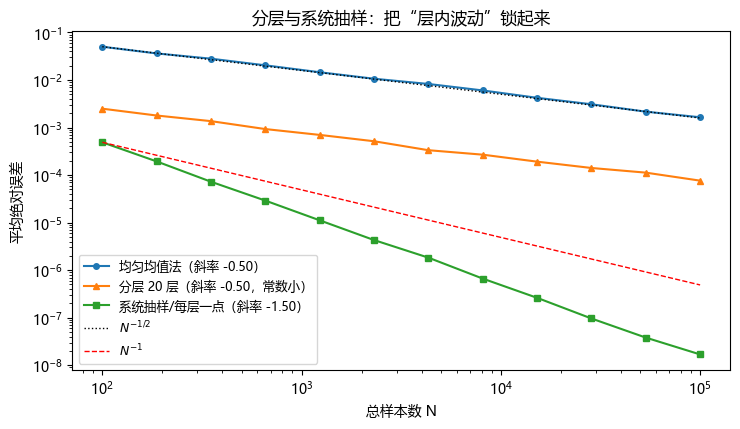

In [23]:
Ns = np.geomspace(100, 100_000, 12).astype(int)
errs_uni, errs_strat, errs_sys = [], [], []
reps = 400
for N in Ns:
    m = 20
    eu, es, ey = [], [], []
    for _ in range(reps):
        eu.append(g(rng.random(N)).mean() - I)
        per = N // m
        xs = (np.arange(m)[:, None] + rng.random((m, per))) / m
        es.append((g(xs).mean(axis=1)).mean() - I)
        ys = (np.arange(N) + rng.random(N)) / N      # 系统抽样：每层一点
        ey.append(g(ys).mean() - I)
    errs_uni.append(np.abs(eu).mean())
    errs_strat.append(np.abs(es).mean())
    errs_sys.append(np.abs(ey).mean())
errs_uni, errs_strat, errs_sys = map(np.array, (errs_uni, errs_strat, errs_sys))
sl = lambda e: np.polyfit(np.log(Ns), np.log(e), 1)[0]
print(f"均匀斜率 {sl(errs_uni):.2f}；分层20层斜率 {sl(errs_strat):.2f}（常数更小）；系统抽样斜率 {sl(errs_sys):.2f}（单调函数 → −1）")

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.loglog(Ns, errs_uni, "o-", ms=4, label=f"均匀均值法（斜率 {sl(errs_uni):.2f}）")
ax.loglog(Ns, errs_strat, "^-", ms=4, label=f"分层 20 层（斜率 {sl(errs_strat):.2f}，常数小）")
ax.loglog(Ns, errs_sys, "s-", ms=4, label=f"系统抽样/每层一点（斜率 {sl(errs_sys):.2f}）")
ax.loglog(Ns, errs_uni[0]*(Ns/Ns[0])**-0.5, "k:", lw=1, label=r"$N^{-1/2}$")
ax.loglog(Ns, errs_sys[0]*(Ns/Ns[0])**-1.0, "r--", lw=1, label=r"$N^{-1}$")
ax.set(title="分层与系统抽样：把“层内波动”锁起来", xlabel="总样本数 N", ylabel="平均绝对误差")
ax.legend(fontsize=9); fig.tight_layout(); save(fig, "out-stratified.png"); plt.show()

## 10.5 五法总决赛

同一目标 π、同一份预算：均匀均值 / hit-or-miss / 对偶 / 分层 / 重要性，误差收敛全线对比。

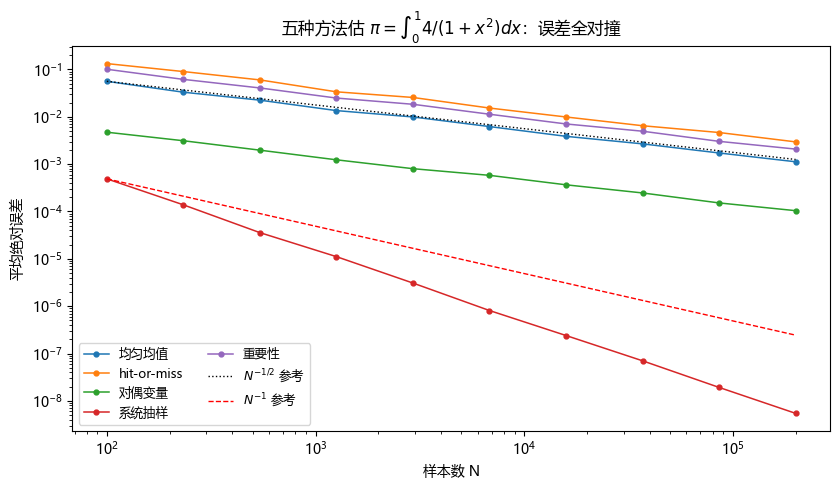

      均匀均值: N=200000 误差 0.00112
hit-or-miss: N=200000 误差 0.00296
      对偶变量: N=200000 误差 0.00010
      系统抽样: N=200000 误差 0.00000
       重要性: N=200000 误差 0.00208


In [24]:
Ns = np.geomspace(100, 200_000, 10).astype(int)
reps = 300
lam = 2.0
methods = {"均匀均值": [], "hit-or-miss": [], "对偶变量": [], "系统抽样": [], "重要性": []}
for N in Ns:
    acc = {k: [] for k in methods}
    for _ in range(reps):
        u = rng.random(N)
        acc["均匀均值"].append(abs(g(u).mean() - I))
        acc["hit-or-miss"].append(abs(4*(rng.random(N) <= g(rng.random(N))/4).mean() - I))
        acc["对偶变量"].append(abs(((g(u) + g(1-u))/2).mean() - I))
        ys = (np.arange(N) + rng.random(N)) / N
        acc["系统抽样"].append(abs(g(ys).mean() - I))
        xi = -np.log(1 - u*(1 - np.exp(-lam))) / lam
        fstar = lam * np.exp(-lam*xi) / (1 - np.exp(-lam))
        acc["重要性"].append(abs((g(xi)/fstar).mean() - I))
    for k in methods:
        methods[k].append(np.mean(acc[k]))

fig, ax = plt.subplots(figsize=(8.5, 5))
for k, v in methods.items():
    ax.loglog(Ns, v, "o-", ms=3.5, lw=1.1, label=k)
ax.loglog(Ns, methods["均匀均值"][0]*(Ns/Ns[0])**-0.5, "k:", lw=1, label=r"$N^{-1/2}$ 参考")
ax.loglog(Ns, methods["系统抽样"][0]*(Ns/Ns[0])**-1.0, "r--", lw=1, label=r"$N^{-1}$ 参考")
ax.set(title=r"五种方法估 $\pi=\int_0^1 4/(1+x^2)dx$：误差全对撞", xlabel="样本数 N", ylabel="平均绝对误差")
ax.legend(ncol=2, fontsize=9)
fig.tight_layout(); save(fig, "out-tournament.png"); plt.show()
for k, v in methods.items():
    print(f"{k:>10}: N=200000 误差 {v[-1]:.5f}")